# 4.3: detección propia de QRS (Pan-Tompkins a 100 Hz)

**Qué hace.** Detecta los picos R directamente del ECG, sin usar las marcas `.qrs` de la base, que son automáticas (`sqrs125`) y no están auditadas. Etapas clásicas de Pan y Tompkins (1985): pasabanda 5–15 Hz ida y vuelta, derivada de 5 puntos, cuadrado, integración en 150 ms y umbrales adaptativos con búsqueda hacia atrás y descarte de ondas T. Los parámetros están en segundos y en Hz (`config.QRS_*`), así que valen a 100 Hz. No supone la polaridad del R: el cuadrado de la derivada es igual para un R invertido, y para ubicar el pico se mide la polaridad de cada registro.

**Antecedente (antes de fijar estas reglas).** En una primera corrida exploratoria sobre desarrollo, el detector quedaba ciego en a03 (Se 0,51) y a17 (Se 0,78): el umbral quedaba por encima de los QRS y no bajaba. Se agregó que los umbrales se vuelvan a aprender si la búsqueda hacia atrás falla. Ese cambio se hizo mirando datos de desarrollo y se declara acá. Los parámetros de Pan y Tompkins no se ajustaron con datos.

**Reglas (fijadas antes de correr).**
1. **Pregunta:** ¿el detector propio puede reemplazar a las `.qrs` en el pipeline?
2. **Validación contra las `.qrs` (descriptiva, no decide):** sensibilidad (Se) y valor predictivo positivo (VPP) con tolerancia de 100 ms, por registro y con todos los latidos juntos, en los 47 registros de desarrollo.
3. **Revisión manual:** como las `.qrs` tienen errores, una discrepancia no es necesariamente un error del detector. Se juntan todas las discrepancias de los 47 registros (falsos positivos y falsos negativos) y se sortean **50** con semilla 2026, **antes de mirarlas**. Cada una se clasifica viendo 10 s de ECG en: *error del detector*, *error de las `.qrs`* o *dudosa*. Se reporta la proporción de cada clase.
4. **Decisión (esquema v3 §7.4):** F con los picos del detector propio contra F con las `.qrs`, sobre los mismos 22.123 minutos de E3a, con 2.000 remuestreos por sujeto. **Se adopta el detector si es no inferior en las dos medidas** (AUC por minuto y acierto por registro; límite inferior del IC 95 % de la diferencia ≥ −0,02). Si no, se siguen usando las `.qrs` y el detector queda como validación.
5. **Minutos:** si con el detector propio algún minuto de los 22.123 queda sin F, se reporta cuántos y la comparación se hace sobre los minutos que tienen F con los dos.
6. **Control (no decide):** la métrica de E1 (coherencia entre el EDR por área y la respiración real) en los 8 registros con respiración, como en `07`.

In [2]:
from google.colab import drive
from pathlib import Path
import os
import sys

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/TP-PSB-G8-main")
assert (ROOT / "src" / "config.py").exists(), "Revisá la ruta."

os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

Mounted at /content/drive


In [3]:
%pip install -q -r requirements.txt

In [4]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import RESULTS_DIR, SEED, SPLIT_CSV
from src.data import load_ecg, load_qrs
from src.qrs.pan_tompkins import detect_r_peaks, validate_against_reference

FIG = RESULTS_DIR / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8})
AZUL, NARANJA, GRIS, TINTA = "#2a78d6", "#eb6834", "#a3a29c", "#2b2b2b"
split = pd.read_csv(SPLIT_CSV).set_index("record")
DEV = list(split.index[split.set == "dev"])
N_REVISION = 50
print(len(DEV), "registros de desarrollo")

47 registros de desarrollo


## 1. Verificación inicial del detector

Se prueba el detector propio en un registro de desarrollo y se
comparan sus detecciones con las marcas QRS de la base, utilizando
la tolerancia de 100 ms prevista.

Las marcas de referencia son automáticas. Por eso, una discrepancia
no implica necesariamente un error del detector propio.

Registro: a01
Latidos de referencia: 29938
Latidos detectados: 29944
Tiempo: 1.4 segundos


,Se,VPP,TP,FP,FN
a01,1.0,0.9998,29938,6,0


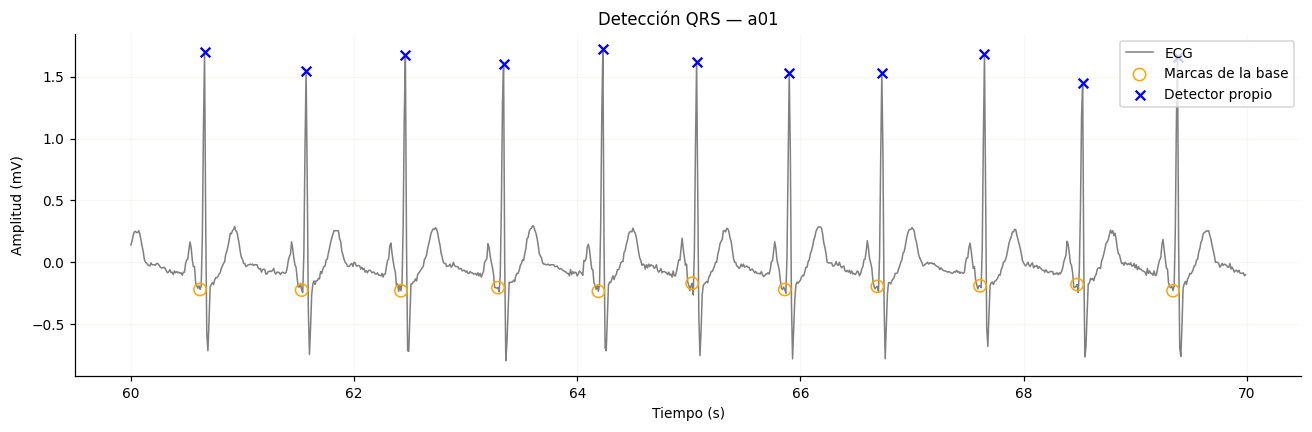

In [4]:
import time

registro = "a01"
assert registro in DEV

ecg, fs = load_ecg(registro)
referencia = load_qrs(registro)

inicio = time.time()

# El detector aplica internamente su preprocesamiento Pan–Tompkins.
detectados = detect_r_peaks(ecg, fs)

metricas = validate_against_reference(
    detected=detectados,
    reference=referencia,
    fs=fs,
    tol=0.10
)

print("Registro:", registro)
print("Latidos de referencia:", len(referencia))
print("Latidos detectados:", len(detectados))
print(f"Tiempo: {time.time() - inicio:.1f} segundos")

display(pd.DataFrame([metricas], index=[registro]))

# Mostrar un tramo fijo de 10 segundos, sin elegirlo por el resultado.
inicio_s, fin_s = 60, 70
i, j = int(inicio_s * fs), int(fin_s * fs)

ref_tramo = referencia[(referencia >= i) & (referencia < j)]
det_tramo = detectados[(detectados >= i) & (detectados < j)]

plt.figure(figsize=(12, 4))
plt.plot(
    np.arange(i, j) / fs,
    ecg[i:j],
    color="gray",
    linewidth=1,
    label="ECG"
)
plt.scatter(
    ref_tramo / fs, ecg[ref_tramo],
    marker="o", facecolors="none", edgecolors="orange",
    s=65, label="Marcas de la base", zorder=3
)
plt.scatter(
    det_tramo / fs, ecg[det_tramo],
    marker="x", color="blue",
    s=40, label="Detector propio", zorder=4
)
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (mV)")
plt.title(f"Detección QRS — {registro}")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [5]:
# Identificar las detecciones y referencias que quedaron sin pareja.
# Usa el mismo emparejamiento que validate_against_reference.
def encontrar_discrepancias(detected, reference, fs, tol=0.10):
    det = np.sort(np.asarray(detected, dtype=int))
    ref = np.sort(np.asarray(reference, dtype=int))

    i = j = 0
    extras, faltantes = [], []

    while i < len(det) and j < len(ref):
        if abs(det[i] - ref[j]) <= tol * fs:
            i += 1
            j += 1
        elif det[i] < ref[j]:
            extras.append(det[i])
            i += 1
        else:
            faltantes.append(ref[j])
            j += 1

    extras.extend(det[i:])
    faltantes.extend(ref[j:])

    return extras, faltantes


CACHE_QRS = RESULTS_DIR / "qrs" / "pan_tompkins_v1"
CACHE_QRS.mkdir(parents=True, exist_ok=True)

filas_metricas = []
filas_discrepancias = []

for numero, rec in enumerate(DEV, start=1):
    ruta = CACHE_QRS / f"{rec}.npz"

    # Guardar las detecciones para no repetir el cálculo
    if ruta.exists():
        with np.load(ruta) as guardado:
            det = guardado["detected"]
            ref = guardado["reference"]
            fs_rec = float(guardado["fs"])
    else:
        x, fs_rec = load_ecg(rec)
        ref = load_qrs(rec)
        det = detect_r_peaks(x, fs_rec)

        np.savez_compressed(
            ruta,
            detected=det,
            reference=ref,
            fs=fs_rec
        )

    medidas = validate_against_reference(det, ref, fs_rec, tol=0.10)
    extras, faltantes = encontrar_discrepancias(det, ref, fs_rec)

    assert len(extras) == medidas["FP"]
    assert len(faltantes) == medidas["FN"]

    filas_metricas.append({"record": rec, **medidas})

    for tipo, muestras in [("FP", extras), ("FN", faltantes)]:
        for muestra in muestras:
            filas_discrepancias.append({
                "record": rec,
                "tipo": tipo,
                "sample": int(muestra),
                "tiempo_s": float(muestra / fs_rec)
            })

    print(
        f"[{numero}/{len(DEV)}] {rec}: "
        f"Se={medidas['Se']:.4f}, VPP={medidas['VPP']:.4f}",
        flush=True
    )

metricas_qrs = pd.DataFrame(filas_metricas).set_index("record")

discrepancias_qrs = pd.DataFrame(
    filas_discrepancias,
    columns=["record", "tipo", "sample", "tiempo_s"]
)

metricas_qrs.to_csv(CACHE_QRS / "metricas_por_registro.csv")
discrepancias_qrs.to_csv(
    CACHE_QRS / "discrepancias.csv", index=False
)

# Resultado global: sumar los conteos, no promediar porcentajes
totales = metricas_qrs[["TP", "FP", "FN"]].sum()
tp, fp, fn = totales["TP"], totales["FP"], totales["FN"]

global_qrs = pd.DataFrame([{
    "Se": tp / (tp + fn) if tp + fn else np.nan,
    "VPP": tp / (tp + fp) if tp + fp else np.nan,
    "TP": tp,
    "FP": fp,
    "FN": fn
}], index=["Todos los latidos"])

display(global_qrs.round(4))

print("Cinco registros con menor sensibilidad:")
display(metricas_qrs.sort_values("Se").head().round(4))

print("Cinco registros con menor VPP:")
display(metricas_qrs.sort_values("VPP").head().round(4))

[1/47] a01: Se=1.0000, VPP=0.9998
[2/47] a02: Se=0.9969, VPP=0.8215
[3/47] a03: Se=0.9982, VPP=0.9992
[4/47] a04: Se=0.9984, VPP=0.9980
[5/47] a05: Se=0.9985, VPP=0.9989
[6/47] a08: Se=0.9991, VPP=0.9991
[7/47] a09: Se=1.0000, VPP=0.9992
[8/47] a10: Se=0.9994, VPP=0.9992
[9/47] a12: Se=0.9975, VPP=0.9361
[10/47] a13: Se=0.9982, VPP=0.9981
[11/47] a14: Se=1.0000, VPP=0.9998
[12/47] a15: Se=0.9983, VPP=0.9985
[13/47] a17: Se=0.9812, VPP=0.9799
[14/47] a18: Se=0.9998, VPP=0.9988
[15/47] a19: Se=0.9996, VPP=0.9997
[16/47] a20: Se=0.9822, VPP=0.9809
[17/47] b01: Se=0.9991, VPP=0.9987
[18/47] b02: Se=0.9823, VPP=0.9958
[19/47] b03: Se=0.9940, VPP=0.9932
[20/47] c01: Se=0.9947, VPP=0.9598
[21/47] c02: Se=0.9974, VPP=0.9637
[22/47] c03: Se=0.9993, VPP=0.9988
[23/47] c06: Se=0.9950, VPP=0.9920
[24/47] c07: Se=0.9972, VPP=0.9923
[25/47] c09: Se=0.9963, VPP=0.9411
[26/47] c10: Se=0.9975, VPP=0.9504
[27/47] x03: Se=0.9991, VPP=0.9989
[28/47] x04: Se=0.9980, VPP=0.9673
[29/47] x05: Se=0.9985, VPP=0

,Se,VPP,TP,FP,FN
Todos los latidos,0.9957,0.9719,1546853,44728,6641


Cinco registros con menor sensibilidad:


,Se,VPP,TP,FP,FN
record,,,,,
x17,0.9211,0.5892,18001,12550,1542
a17,0.9812,0.9799,35788,734,687
a20,0.9822,0.9809,33865,659,614
b02,0.9823,0.9958,34770,148,626
x20,0.9865,0.9818,38581,715,527


Cinco registros con menor VPP:


,Se,VPP,TP,FP,FN
record,,,,,
x17,0.9211,0.5892,18001,12550,1542
a02,0.9969,0.8215,35131,7632,111
x25,0.9986,0.8929,32507,3901,44
x14,0.9933,0.9282,38814,3001,260
a12,0.9975,0.9361,33856,2312,84


In [6]:
# Identificar las detecciones y referencias que quedaron sin pareja.
# Usa el mismo emparejamiento que validate_against_reference.
def encontrar_discrepancias(detected, reference, fs, tol=0.10):
    det = np.sort(np.asarray(detected, dtype=int))
    ref = np.sort(np.asarray(reference, dtype=int))

    i = j = 0
    extras, faltantes = [], []

    while i < len(det) and j < len(ref):
        if abs(det[i] - ref[j]) <= tol * fs:
            i += 1
            j += 1
        elif det[i] < ref[j]:
            extras.append(det[i])
            i += 1
        else:
            faltantes.append(ref[j])
            j += 1

    extras.extend(det[i:])
    faltantes.extend(ref[j:])

    return extras, faltantes


CACHE_QRS = RESULTS_DIR / "qrs" / "pan_tompkins_v1"
CACHE_QRS.mkdir(parents=True, exist_ok=True)

filas_metricas = []
filas_discrepancias = []

for numero, rec in enumerate(DEV, start=1):
    ruta = CACHE_QRS / f"{rec}.npz"

    # Guardar las detecciones para no repetir el cálculo
    if ruta.exists():
        with np.load(ruta) as guardado:
            det = guardado["detected"]
            ref = guardado["reference"]
            fs_rec = float(guardado["fs"])
    else:
        x, fs_rec = load_ecg(rec)
        ref = load_qrs(rec)
        det = detect_r_peaks(x, fs_rec)

        np.savez_compressed(
            ruta,
            detected=det,
            reference=ref,
            fs=fs_rec
        )

    medidas = validate_against_reference(det, ref, fs_rec, tol=0.10)
    extras, faltantes = encontrar_discrepancias(det, ref, fs_rec)

    assert len(extras) == medidas["FP"]
    assert len(faltantes) == medidas["FN"]

    filas_metricas.append({"record": rec, **medidas})

    for tipo, muestras in [("FP", extras), ("FN", faltantes)]:
        for muestra in muestras:
            filas_discrepancias.append({
                "record": rec,
                "tipo": tipo,
                "sample": int(muestra),
                "tiempo_s": float(muestra / fs_rec)
            })

    print(
        f"[{numero}/{len(DEV)}] {rec}: "
        f"Se={medidas['Se']:.4f}, VPP={medidas['VPP']:.4f}",
        flush=True
    )

metricas_qrs = pd.DataFrame(filas_metricas).set_index("record")

discrepancias_qrs = pd.DataFrame(
    filas_discrepancias,
    columns=["record", "tipo", "sample", "tiempo_s"]
)

metricas_qrs.to_csv(CACHE_QRS / "metricas_por_registro.csv")
discrepancias_qrs.to_csv(
    CACHE_QRS / "discrepancias.csv", index=False
)

# Resultado global: sumar los conteos, no promediar porcentajes
totales = metricas_qrs[["TP", "FP", "FN"]].sum()
tp, fp, fn = totales["TP"], totales["FP"], totales["FN"]

global_qrs = pd.DataFrame([{
    "Se": tp / (tp + fn) if tp + fn else np.nan,
    "VPP": tp / (tp + fp) if tp + fp else np.nan,
    "TP": tp,
    "FP": fp,
    "FN": fn
}], index=["Todos los latidos"])

display(global_qrs.round(4))

print("Cinco registros con menor sensibilidad:")
display(metricas_qrs.sort_values("Se").head().round(4))

print("Cinco registros con menor VPP:")
display(metricas_qrs.sort_values("VPP").head().round(4))

[1/47] a01: Se=1.0000, VPP=0.9998
[2/47] a02: Se=0.9969, VPP=0.8215
[3/47] a03: Se=0.9982, VPP=0.9992
[4/47] a04: Se=0.9984, VPP=0.9980
[5/47] a05: Se=0.9985, VPP=0.9989
[6/47] a08: Se=0.9991, VPP=0.9991
[7/47] a09: Se=1.0000, VPP=0.9992
[8/47] a10: Se=0.9994, VPP=0.9992
[9/47] a12: Se=0.9975, VPP=0.9361
[10/47] a13: Se=0.9982, VPP=0.9981
[11/47] a14: Se=1.0000, VPP=0.9998
[12/47] a15: Se=0.9983, VPP=0.9985
[13/47] a17: Se=0.9812, VPP=0.9799
[14/47] a18: Se=0.9998, VPP=0.9988
[15/47] a19: Se=0.9996, VPP=0.9997
[16/47] a20: Se=0.9822, VPP=0.9809
[17/47] b01: Se=0.9991, VPP=0.9987
[18/47] b02: Se=0.9823, VPP=0.9958
[19/47] b03: Se=0.9940, VPP=0.9932
[20/47] c01: Se=0.9947, VPP=0.9598
[21/47] c02: Se=0.9974, VPP=0.9637
[22/47] c03: Se=0.9993, VPP=0.9988
[23/47] c06: Se=0.9950, VPP=0.9920
[24/47] c07: Se=0.9972, VPP=0.9923
[25/47] c09: Se=0.9963, VPP=0.9411
[26/47] c10: Se=0.9975, VPP=0.9504
[27/47] x03: Se=0.9991, VPP=0.9989
[28/47] x04: Se=0.9980, VPP=0.9673
[29/47] x05: Se=0.9985, VPP=0

,Se,VPP,TP,FP,FN
Todos los latidos,0.9957,0.9719,1546853,44728,6641


Cinco registros con menor sensibilidad:


,Se,VPP,TP,FP,FN
record,,,,,
x17,0.9211,0.5892,18001,12550,1542
a17,0.9812,0.9799,35788,734,687
a20,0.9822,0.9809,33865,659,614
b02,0.9823,0.9958,34770,148,626
x20,0.9865,0.9818,38581,715,527


Cinco registros con menor VPP:


,Se,VPP,TP,FP,FN
record,,,,,
x17,0.9211,0.5892,18001,12550,1542
a02,0.9969,0.8215,35131,7632,111
x25,0.9986,0.8929,32507,3901,44
x14,0.9933,0.9282,38814,3001,260
a12,0.9975,0.9361,33856,2312,84


In [7]:
RUTA_REVISION = ROOT / "docs" / "revision_qrs_50.csv"
RUTA_REVISION.parent.mkdir(parents=True, exist_ok=True)

if RUTA_REVISION.exists():
    revision_qrs = pd.read_csv(RUTA_REVISION, keep_default_na=False)
    print("Se conserva la selección ya guardada.")
else:
    # Orden fijo antes del sorteo para que sea reproducible
    candidatas = (
        discrepancias_qrs
        .sort_values(["record", "sample", "tipo"])
        .reset_index(drop=True)
    )

    rng = np.random.default_rng(2026)
    elegidas = rng.choice(
        len(candidatas),
        size=min(50, len(candidatas)),
        replace=False
    )

    revision_qrs = candidatas.iloc[elegidas].copy().reset_index(drop=True)
    revision_qrs.insert(0, "caso", np.arange(1, len(revision_qrs) + 1))
    revision_qrs["clasificacion"] = ""
    revision_qrs["comentario"] = ""

    revision_qrs.to_csv(RUTA_REVISION, index=False)
    print("Selección sorteada y guardada antes de la revisión.")

print("Discrepancias totales:", len(discrepancias_qrs))
print("Casos seleccionados:", len(revision_qrs))

Selección sorteada y guardada antes de la revisión.
Discrepancias totales: 51369
Casos seleccionados: 50


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_ecg

# Recuperar los archivos guardados, sin repetir el procesamiento
CACHE_QRS = ROOT / "results" / "qrs" / "pan_tompkins_v1"
RUTA_REVISION = ROOT / "docs" / "revision_qrs_50.csv"

if not RUTA_REVISION.exists():
    raise FileNotFoundError(
        "No se encontró el CSV de revisión. Revisá la ruta antes de continuar."
    )

revision_qrs = pd.read_csv(
    RUTA_REVISION,
    keep_default_na=False
)

categorias = [
    "error del detector",
    "error de las marcas de la base",
    "dudoso"
]

revisados = revision_qrs["clasificacion"].isin(categorias).sum()

print(f"Revisión recuperada: {revisados}/{len(revision_qrs)} casos.")
print("Archivos de detecciones encontrados:", len(list(CACHE_QRS.glob("*.npz"))))

Revisión recuperada: 6/50 casos.
Archivos de detecciones encontrados: 47


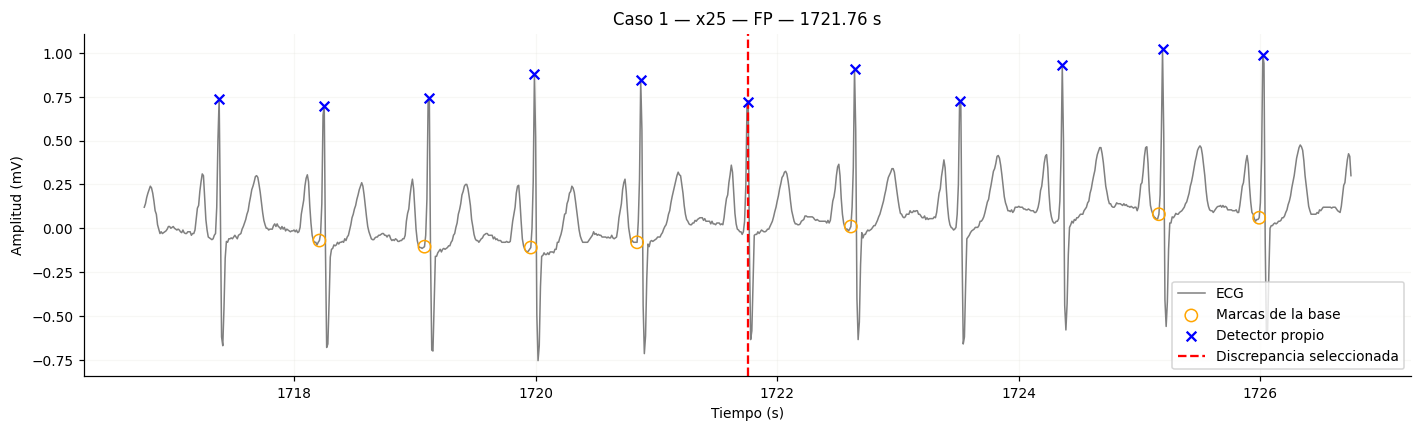

In [7]:
def mostrar_caso(numero):
    caso = revision_qrs.loc[revision_qrs["caso"] == numero].iloc[0]
    rec = caso["record"]
    muestra = int(caso["sample"])

    x, fs_rec = load_ecg(rec)

    with np.load(CACHE_QRS / f"{rec}.npz") as guardado:
        det = guardado["detected"]
        ref = guardado["reference"]

    # Ventana de 10 s, desplazada si estamos cerca de un extremo
    ancho = int(round(10 * fs_rec))
    inicio = max(0, min(
        muestra - ancho // 2,
        len(x) - ancho
    ))
    fin = min(len(x), inicio + ancho)

    det_tramo = det[(det >= inicio) & (det < fin)]
    ref_tramo = ref[(ref >= inicio) & (ref < fin)]

    plt.figure(figsize=(13, 4))
    plt.plot(
        np.arange(inicio, fin) / fs_rec,
        x[inicio:fin],
        color="gray",
        linewidth=1,
        label="ECG"
    )
    plt.scatter(
        ref_tramo / fs_rec, x[ref_tramo],
        facecolors="none", edgecolors="orange",
        s=65, label="Marcas de la base", zorder=3
    )
    plt.scatter(
        det_tramo / fs_rec, x[det_tramo],
        marker="x", color="blue",
        s=40, label="Detector propio", zorder=4
    )
    plt.axvline(
        muestra / fs_rec,
        color="red", linestyle="--",
        label="Discrepancia seleccionada"
    )
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Amplitud (mV)")
    plt.title(
        f"Caso {numero} — {rec} — {caso['tipo']} "
        f"— {muestra / fs_rec:.2f} s"
    )
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


mostrar_caso(1)

In [10]:
import ipywidgets as widgets
from IPython.display import display, clear_output
from google.colab import output

output.enable_custom_widget_manager()

# Recuperar la selección original y las revisiones existentes
revision_qrs = pd.read_csv(RUTA_REVISION, keep_default_na=False)

CATEGORIAS = [
    "error del detector",
    "error de las marcas de la base",
    "dudoso"
]

pendientes = revision_qrs.loc[
    ~revision_qrs["clasificacion"].isin(CATEGORIAS), "caso"
].tolist()

selector = widgets.Dropdown(
    options=[
        (f"Caso {int(fila.caso)} — {fila.record}", int(fila.caso))
        for fila in revision_qrs.itertuples()
    ],
    value=int(pendientes[0]) if pendientes else int(revision_qrs.iloc[0]["caso"]),
    description="Ver caso:",
    layout=widgets.Layout(width="350px")
)

progreso = widgets.HTML()

comentario = widgets.Textarea(
    placeholder="Comentario opcional: qué observaste en la señal.",
    layout=widgets.Layout(width="100%", height="65px")
)

grafico = widgets.Output()
aviso = widgets.HTML()

botones = [
    widgets.Button(
        description=texto,
        layout=widgets.Layout(width="100%", height="36px")
    )
    for texto in [
        "Error del detector",
        "Error de las marcas de la base",
        "Dudoso"
    ]
]


def actualizar_vista(*_):
    numero = selector.value
    fila = revision_qrs.loc[revision_qrs["caso"] == numero].iloc[0]

    completos = revision_qrs["clasificacion"].isin(CATEGORIAS).sum()
    categoria = fila["clasificacion"] or "Pendiente"

    progreso.value = (
        f"<b>Revisados: {completos}/{len(revision_qrs)}</b>"
        f" — Clasificación actual: {categoria}"
    )
    comentario.value = str(fila["comentario"])

    with grafico:
        clear_output(wait=True)
        mostrar_caso(numero)


def guardar_y_avanzar(categoria):
    for boton in botones:
        boton.disabled = True

    numero = selector.value
    seleccion = revision_qrs["caso"] == numero

    anteriores = revision_qrs.loc[
        seleccion, ["clasificacion", "comentario"]
    ].copy()

    try:
        revision_qrs.loc[seleccion, "clasificacion"] = categoria
        revision_qrs.loc[seleccion, "comentario"] = comentario.value.strip()
        revision_qrs.to_csv(RUTA_REVISION, index=False)

    except Exception as error:
        revision_qrs.loc[
            seleccion, ["clasificacion", "comentario"]
        ] = anteriores.to_numpy()

        aviso.value = f"No se pudo guardar: {error}"

    else:
        pendientes = revision_qrs.loc[
            ~revision_qrs["clasificacion"].isin(CATEGORIAS), "caso"
        ].tolist()

        aviso.value = f"Caso {numero} guardado."

        if pendientes:
            # Continuar al siguiente pendiente, sin repetir los revisados
            siguientes = [n for n in pendientes if n > numero]
            selector.value = int(
                siguientes[0] if siguientes else pendientes[0]
            )
        else:
            aviso.value = "<b>Revisión completa. Todas las respuestas están guardadas.</b>"
            actualizar_vista()

    finally:
        for boton in botones:
            boton.disabled = False


selector.observe(actualizar_vista, names="value")

for boton, categoria in zip(botones, CATEGORIAS):
    boton.on_click(
        lambda _, categoria=categoria: guardar_y_avanzar(categoria)
    )

display(widgets.VBox([
    progreso,
    selector,
    grafico,
    comentario,
    widgets.VBox(botones),
    aviso
]))

actualizar_vista()

In [9]:
BASE = "error de las marcas de la base"
DETECTOR = "error del detector"
DUDOSO = "dudoso"

tanda = {
    31: ("x20", DUDOSO, "Grandes desplazamientos y distorsión de señal."),
    32: ("a02", DUDOSO, "Detección dentro de una ráfaga de ruido."),
    33: ("a12", BASE, "Complejo estrecho negativo similar a los vecinos, sin referencia cercana."),
    34: ("x14", BASE, "Complejo reconocible en secuencia de latidos, sin referencia cercana."),
    35: ("x17", DETECTOR, "Detección adicional al finalizar la onda posterior al QRS."),
    36: ("x14", DUDOSO, "Marca cercana y complejo distorsionado; posible diferencia de localización."),
    37: ("x17", DETECTOR, "Detección posterior al QRS sin otro complejo visible."),
    38: ("c02", DUDOSO, "Complejo próximo a referencia con ruido; atribución incierta."),
    39: ("x17", DETECTOR, "Detección adicional posterior al QRS."),
    40: ("a02", BASE, "QRS claro sin marca correspondiente."),
    41: ("x17", DETECTOR, "Detección adicional al finalizar la onda posterior al QRS."),
    42: ("x17", DETECTOR, "Detección posterior al QRS sin otro complejo visible."),
    43: ("a02", BASE, "QRS estrecho similar a los vecinos, sin referencia cercana."),
    44: ("x17", DETECTOR, "Detección adicional posterior al QRS."),
    45: ("x17", BASE, "La posición seleccionada corresponde al QRS negativo, sin referencia cercana."),
    46: ("x34", BASE, "Complejo negativo estrecho similar a los vecinos, sin referencia cercana."),
    47: ("c09", DETECTOR, "Oscilación rápida repetitiva sin QRS reconocible."),
    48: ("c09", DETECTOR, "Oscilación rápida repetitiva sin QRS reconocible."),
    49: ("x17", DETECTOR, "Detección adicional al finalizar la onda posterior al QRS.")
}

revision_qrs = pd.read_csv(RUTA_REVISION, keep_default_na=False)

# Validar antes de modificar
for numero, (registro, categoria, comentario) in tanda.items():
    fila = revision_qrs.loc[revision_qrs["caso"] == numero]
    assert len(fila) == 1
    assert fila.iloc[0]["record"] == registro, f"Revisar caso {numero}"

for numero, (_, categoria, comentario) in tanda.items():
    seleccion = revision_qrs["caso"] == numero
    revision_qrs.loc[seleccion, "clasificacion"] = categoria
    revision_qrs.loc[seleccion, "comentario"] = comentario

revision_qrs.to_csv(RUTA_REVISION, index=False)

completos = revision_qrs["clasificacion"].isin([BASE, DETECTOR, DUDOSO])
print(f"Guardado. Revisados: {completos.sum()}/{len(revision_qrs)}")
print("Pendientes:", revision_qrs.loc[~completos, "caso"].tolist())

Guardado. Revisados: 48/50
Pendientes: [12, 50]


## Comparación de F con el detector propio

Se recalculan RR y EDR utilizando las detecciones propias, manteniendo
el resto del procesamiento vigente y sin Wiener.

Se comparará F con la obtenida usando las marcas de la base, sobre
los minutos de evaluación previstos. La revisión manual de las
50 discrepancias permanece pendiente y no se utiliza para ajustar
el detector.

In [14]:
from src.config import ECG_FILTER
from src.preprocessing.filters import design_bandpass, apply_zero_phase
from src.qrs.pan_tompkins import r_peaks_from_marks
from src.qrs.rr_clean import clean_rr
from src.features.edr import qrs_reference, compute_edr
from src.features.coupling import resample_uniform
from src.features.build import record_series, record_minute_table

BANDA_F = {"ap": (0.01, 0.05)}

def series_detector_propio(rec):
    """Mismo procesamiento del grupo, usando los QRS propios."""
    ecg_rec, fs_rec = load_ecg(rec)

    with np.load(CACHE_QRS / f"{rec}.npz") as archivo:
        marcas_propias = archivo["detected"]

    x = apply_zero_phase(
        ecg_rec, design_bandpass(fs_rec, *ECG_FILTER)
    )

    off, sign = qrs_reference(x, marcas_propias, fs_rec)

    t_r, _ = r_peaks_from_marks(
        x, marcas_propias, fs_rec, off, sign, refine=True
    )
    t_rr, rr, corregidos = clean_rr(t_r)

    # EDR también calculado con las marcas propias
    t_edr, edr = compute_edr(
        ecg_rec, marcas_propias, fs_rec,
        method="area", filt=ECG_FILTER
    )

    fs_uniforme = 2.0
    tu_rr, rr_u = resample_uniform(t_rr, rr, fs_uniforme)
    tu_edr, edr_u = resample_uniform(t_edr, edr, fs_uniforme)

    inicio = max(tu_rr[0], tu_edr[0])
    fin = min(tu_rr[-1], tu_edr[-1])

    keep_rr = (tu_rr >= inicio) & (tu_rr <= fin)
    keep_edr = (tu_edr >= inicio) & (tu_edr <= fin)

    np.testing.assert_allclose(tu_rr[keep_rr], tu_edr[keep_edr])

    return {
        "t": tu_rr[keep_rr],
        "rr": rr_u[keep_rr],
        "edr": edr_u[keep_edr],
        "edrs": {"area": edr_u[keep_edr]},
        "fs": fs_uniforme,
        "t_rr": t_rr,
        "rr_beats": rr,
        "corrected": corregidos,
        "sign": sign,
        "edr_method": "area"
    }


def calcular_comparacion_qrs(rec):
    tablas = {}

    for nombre, series in [
        ("base", record_series(rec, edr_method="area")),
        ("propio", series_detector_propio(rec))
    ]:
        tabla = record_minute_table(
            rec,
            width_s=240,
            bands=BANDA_F,
            series=series,
            edr_method="area",
            estimator="welch3"
        )

        tabla[f"F_{nombre}"] = np.log(
            np.maximum(tabla["xp_ap"], 1e-12)
        )

        tablas[nombre] = tabla[
            ["record", "minute", "label", "corrected", f"F_{nombre}"]
        ].rename(columns={
            "label": f"label_{nombre}",
            "corrected": f"corrected_{nombre}"
        })

    resultado = tablas["base"].merge(
        tablas["propio"],
        on=["record", "minute"],
        how="outer",
        validate="one_to_one"
    )

    comunes = resultado["label_base"].notna() & resultado["label_propio"].notna()
    assert (
        resultado.loc[comunes, "label_base"]
        == resultado.loc[comunes, "label_propio"]
    ).all()

    return resultado

In [15]:
import time

CACHE_F_QRS = CACHE_QRS / "comparacion_F_v1"
CACHE_F_QRS.mkdir(parents=True, exist_ok=True)

inicio = time.time()

for numero, rec in enumerate(DEV, start=1):
    ruta = CACHE_F_QRS / f"{rec}.parquet"

    if ruta.exists():
        print(f"[{numero}/{len(DEV)}] {rec}: ya guardado", flush=True)
        continue

    print(f"[{numero}/{len(DEV)}] {rec}: calculando F...", flush=True)

    tabla = calcular_comparacion_qrs(rec)
    tabla.to_parquet(ruta, index=False)

comparacion_f_qrs = pd.concat(
    [pd.read_parquet(CACHE_F_QRS / f"{rec}.parquet") for rec in DEV],
    ignore_index=True
)

print(f"\nTiempo: {(time.time() - inicio) / 60:.1f} minutos")
print("Registros:", comparacion_f_qrs["record"].nunique())
display(comparacion_f_qrs.head())

[1/47] a01: calculando F...
[2/47] a02: calculando F...
[3/47] a03: calculando F...
[4/47] a04: calculando F...
[5/47] a05: calculando F...
[6/47] a08: calculando F...
[7/47] a09: calculando F...
[8/47] a10: calculando F...
[9/47] a12: calculando F...
[10/47] a13: calculando F...
[11/47] a14: calculando F...
[12/47] a15: calculando F...
[13/47] a17: calculando F...
[14/47] a18: calculando F...
[15/47] a19: calculando F...
[16/47] a20: calculando F...
[17/47] b01: calculando F...
[18/47] b02: calculando F...
[19/47] b03: calculando F...
[20/47] c01: calculando F...
[21/47] c02: calculando F...
[22/47] c03: calculando F...
[23/47] c06: calculando F...
[24/47] c07: calculando F...
[25/47] c09: calculando F...
[26/47] c10: calculando F...
[27/47] x03: calculando F...
[28/47] x04: calculando F...
[29/47] x05: calculando F...
[30/47] x07: calculando F...
[31/47] x08: calculando F...
[32/47] x09: calculando F...
[33/47] x10: calculando F...
[34/47] x12: calculando F...
[35/47] x14: calculando

,record,minute,label_base,corrected_base,F_base,label_propio,corrected_propio,F_propio
0,a01,2,0.0,0.013514,-6.639947,0,0.013514,-6.643541
1,a01,3,0.0,0.000000,-6.628961,0,0.000000,-6.634224
2,a01,4,0.0,0.000000,-6.744122,0,0.000000,-6.746496
3,a01,5,0.0,0.000000,-7.735282,0,0.000000,-7.737917
4,a01,6,0.0,0.000000,-7.153982,0,0.000000,-7.171929


In [16]:
from src.features.variants import coupling_variants, hrv_variants
from src.stats.compare import compare_variants, agreement_compare

cache_e3 = RESULTS_DIR / "e3"

coup = pd.read_parquet(cache_e3 / "acoplamiento.parquet")
hrv = pd.read_parquet(cache_e3 / "hrv.parquet")

wc, _ = coupling_variants(coup)
wh, _ = hrv_variants(hrv)

info = (
    coup.loc[
        (coup["edr"] == "area")
        & (coup["window"] == 512)
        & (coup["estimator"] == "welch3")
    ]
    .set_index(["record", "minute"])[["label", "corrected"]]
)

# Misma selección de minutos que en E3
idx = (
    wc.dropna().index
    .intersection(wh.dropna().index)
    .intersection(
        info.index[
            info["label"].isin([0, 1])
            & (info["corrected"] <= 0.20)
        ]
    )
)

evaluacion = (
    comparacion_f_qrs
    .set_index(["record", "minute"])
    .reindex(idx)
)

validos = np.isfinite(evaluacion[["F_base", "F_propio"]]).all(axis=1)

print("Minutos previstos:", len(idx))
print("Sin F calculable con ambos métodos:", int((~validos).sum()))

evaluacion = evaluacion.loc[validos].copy()

# Verificar que el camino de referencia no cambió
np.testing.assert_allclose(
    evaluacion["F_base"],
    wc.loc[evaluacion.index, "area|240s|welch3|apnea|potencia sola"],
    rtol=1e-8,
    atol=1e-10
)

F_qrs = evaluacion[["F_base", "F_propio"]]
y_qrs = info.loc[evaluacion.index, "label"].to_numpy(dtype=int)
recs_qrs = evaluacion.index.get_level_values("record").to_numpy()

particion = pd.read_csv(SPLIT_CSV).set_index("record")
sujetos_qrs = particion.loc[recs_qrs, "subject"].to_numpy()

print("Minutos evaluados:", len(evaluacion))
print("La F de referencia coincide con la ya calculada.")
print(
    "Minutos evaluados con más de 20 % de RR corregidos "
    "usando el detector propio:",
    int((evaluacion["corrected_propio"] > 0.20).sum())
)

del coup, hrv, wc, wh

Minutos previstos: 22125
Sin F calculable con ambos métodos: 0
Minutos evaluados: 22125
La F de referencia coincide con la ya calculada.
Minutos evaluados con más de 20 % de RR corregidos usando el detector propio: 144


In [17]:
auc_qrs = compare_variants(
    F_qrs, y_qrs, sujetos_qrs,
    n_boot=2000, seed=2026
)

registro_qrs = agreement_compare(
    F_qrs, y_qrs, recs_qrs, sujetos_qrs,
    n_boot=2000, seed=2026
)

def diferencia_detector(tabla, medida):
    """Diferencia e intervalo: detector propio menos marcas de la base."""
    base = tabla.loc["F_base", medida]
    propio = tabla.loc["F_propio", medida]

    if base >= propio:
        inferior = tabla.loc["F_propio", "dif_lo"]
        superior = tabla.loc["F_propio", "dif_hi"]
    else:
        inferior = -tabla.loc["F_base", "dif_hi"]
        superior = -tabla.loc["F_base", "dif_lo"]

    return {
        "Marcas de la base": base,
        "Detector propio": propio,
        "Diferencia": propio - base,
        "IC95 inferior": inferior,
        "IC95 superior": superior
    }

criterio_qrs = pd.DataFrame({
    "AUC por minuto": diferencia_detector(auc_qrs, "auc"),
    "Spearman por registro": diferencia_detector(
        registro_qrs, "spearman"
    )
}).T

criterio_qrs["Cumple no inferioridad"] = (
    criterio_qrs["IC95 inferior"] >= -0.02
)

display(criterio_qrs.round(4))

,Marcas de la base,Detector propio,Diferencia,IC95 inferior,IC95 superior,Cumple no inferioridad
AUC por minuto,0.8747,0.8785,0.0038,-0.0004,0.0079,True
Spearman por registro,0.8104,0.7864,-0.0240,-0.0971,0.0194,False


### Resultado de la comparación

El detector propio cumplió no inferioridad en AUC por minuto:
la diferencia fue +0,0038, con IC95 % de −0,0004 a +0,0079.

No cumplió no inferioridad en Spearman por registro:
la diferencia fue −0,0240, con IC95 % de −0,0971 a +0,0194.
El límite inferior quedó por debajo del margen permitido de −0,02.

Como se requiere cumplir ambas medidas, se mantienen las marcas
de la base en el procesamiento vigente. El detector propio queda
implementado y evaluado como alternativa.

No cumplir no inferioridad no demuestra que el detector sea peor.
La revisión manual de las 50 discrepancias permanece pendiente.

## Control del EDR con respiración real

Se compara la coherencia entre el EDR por área y la respiración medida
en los ocho registros disponibles. Se utilizan alternativamente las
marcas de la base y las detecciones propias.

Se mantiene el mismo filtrado y se comparan intervalos temporales
comunes, reutilizando la métrica de validación del proyecto.
Este control es descriptivo.

In [18]:
from src.config import RESP_RECORDS
from src.data import load_respiration
from src.features.edr import compute_edr, validate_edr
from src.features.coupling import resample_uniform, downsample

assert set(RESP_RECORDS).issubset(set(DEV))

filas_control_qrs = []

for numero, rec in enumerate(RESP_RECORDS, start=1):
    print(f"[{numero}/{len(RESP_RECORDS)}] {rec}", flush=True)

    ecg_rec, fs_rec = load_ecg(rec)
    marcas_base = load_qrs(rec)

    with np.load(CACHE_QRS / f"{rec}.npz") as archivo:
        marcas_propias = archivo["detected"]

    # Calcular ambos EDR con la misma función del proyecto
    series_edr = {}

    for nombre, marcas in [
        ("Base", marcas_base),
        ("Propio", marcas_propias)
    ]:
        t, valores = compute_edr(
            ecg_rec, marcas, fs_rec,
            method="area", filt=ECG_FILTER
        )
        series_edr[nombre] = resample_uniform(t, valores, 2.0)

    # Conservar el intervalo temporal común
    inicio = max(v[0][0] for v in series_edr.values())
    fin = min(v[0][-1] for v in series_edr.values())

    comunes = {}

    for nombre, (t, valores) in series_edr.items():
        keep = (t >= inicio) & (t <= fin)
        comunes[nombre] = (t[keep], valores[keep])

    np.testing.assert_allclose(
        comunes["Base"][0], comunes["Propio"][0]
    )

    tiempos = comunes["Base"][0]
    posiciones = np.rint(tiempos * 2).astype(int)

    respiracion, fs_resp = load_respiration(rec)
    resultados_canal = {"Base": [], "Propio": []}
    ventanas_comunes = []

    for canal in ["Resp C", "Resp A", "Resp N"]:
        resp = downsample(respiracion[canal], fs_resp, 2.0)
        dentro = (posiciones >= 0) & (posiciones < len(resp))
        resp_comun = resp[posiciones[dentro]]

        coherencias = {}

        for nombre in ["Base", "Propio"]:
            coherencias[nombre] = validate_edr(
                comunes[nombre][1][dentro],
                resp_comun,
                fs=2.0
            )

        # Comparar exactamente las mismas ventanas válidas
        validas = (
            np.isfinite(coherencias["Base"])
            & np.isfinite(coherencias["Propio"])
        )
        ventanas_comunes.append(int(validas.sum()))

        for nombre in ["Base", "Propio"]:
            resultados_canal[nombre].append(
                np.median(coherencias[nombre][validas])
                if validas.any() else np.nan
            )

    filas_control_qrs.append({
        "Registro": rec,
        "Marcas de la base": np.mean(resultados_canal["Base"]),
        "Detector propio": np.mean(resultados_canal["Propio"]),
        "Mínimo de ventanas comunes por canal": min(ventanas_comunes)
    })

control_resp_qrs = pd.DataFrame(
    filas_control_qrs
).set_index("Registro")

control_resp_qrs["Diferencia"] = (
    control_resp_qrs["Detector propio"]
    - control_resp_qrs["Marcas de la base"]
)

display(control_resp_qrs.round(4))

print("Promedio entre registros:")
display(
    control_resp_qrs[
        ["Marcas de la base", "Detector propio", "Diferencia"]
    ].mean().to_frame("Media").round(4)
)

[1/8] a01
[2/8] a02
[3/8] a03
[4/8] a04
[5/8] b01
[6/8] c01
[7/8] c02
[8/8] c03


,Marcas de la base,Detector propio,Mínimo de ventanas comunes por canal,Diferencia
Registro,,,,
a01,0.5123,0.5130,75,0.0006
a02,0.3390,0.3726,102,0.0336
a03,0.4586,0.4785,238,0.0199
a04,0.3250,0.3270,202,0.0020
b01,0.6298,0.6180,215,-0.0117
c01,0.6308,0.6423,220,0.0115
c02,0.5223,0.5786,244,0.0563
c03,0.7513,0.7508,201,-0.0005


Promedio entre registros:


,Media
Marcas de la base,0.5211
Detector propio,0.5351
Diferencia,0.0140


### Resultado del control y conclusión

La coherencia media entre el EDR y la respiración medida fue 0,5211
utilizando las marcas de la base y 0,5351 con el detector propio.
La diferencia media fue +0,0140, con aumentos en seis de los ocho
registros. Este resultado es descriptivo y no demuestra una mejora
estadísticamente significativa.

El detector propio cumplió no inferioridad en AUC por minuto,
pero no en Spearman por registro. Por lo tanto, se mantienen las
marcas de la base en el procesamiento vigente.

La evaluación automática y el control con respiración real están
completos. La revisión manual de las 50 discrepancias sigue pendiente.

## Decisión

**Se mantienen las marcas `.qrs` de la base.** El detector propio fue no inferior en AUC por minuto (+0,0038; IC −0,0004 a +0,0079), pero no en acierto por registro (−0,0240; IC −0,0971 a +0,0194, por debajo de −0,02). La regla exige las dos medidas. No cumplir no inferioridad no demuestra que el detector sea peor.

**Revisión manual (regla 3).** De las 50 discrepancias sorteadas, 21 son errores del detector, 18 son errores de las marcas `.qrs` y 11 son dudosas. Sin las dudosas, el detector explica el 54 % (21 de 39): una discrepancia con las `.qrs` no es necesariamente un error del detector. La muestra está dominada por x17 (14 de 50), como era esperable con un sorteo sobre todas las discrepancias.

Los errores del detector siguen tres patrones: unos 13 son una detección adicional al final de la onda T en x17 y x12 (limitación conocida: la T empinada pasa la regla de pendiente; test `xfail`); 5 son oscilaciones rápidas al inicio del registro (c01, x04, c09, en los primeros 4 min), donde el detector aprende los umbrales de un tramo con artefacto; y 2 son casos aislados. Los errores de las `.qrs` son en su mayoría QRS claros sin marca, a menudo negativos o bifásicos.

**Control E1** (descriptivo): coherencia EDR–respiración 0,521 con las `.qrs` y 0,535 con el detector propio.